# Lab 1 - K-Means Clustering
## JS07 - Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objectives
1. Understand the core principles of unsupervised learning and centroid-based clustering.
2. Implement the K-Means clustering algorithm using Python and scikit-learn on the Iris dataset.
3. Visualize feature space and cluster assignments along with cluster centroids.
4. Evaluate cluster compactness using Sum of Squared Errors (SSE / Inertia).
5. Apply the Elbow Method to determine the optimal number of clusters ($k$).


## Step 0 - Dataset Description
The Iris dataset characterizes three species of Iris flowers (*Iris-setosa*, *Iris-versicolor*, and *Iris-virginica*) based on four morphological measurements:
- `SepalLengthCm`: Sepal length in centimeters
- `SepalWidthCm`: Sepal width in centimeters
- `PetalLengthCm`: Petal length in centimeters
- `PetalWidthCm`: Petal width in centimeters

Although the dataset includes the ground-truth `Species` label, in this clustering practicum we treat the data as **unlabeled** to study how unsupervised algorithms group observations based purely on geometric similarity in feature space.


## Step 1 - Import Libraries
Import the required data manipulation, mathematical computation, visualization, and machine learning modules.


In [1]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Set aesthetic styling
sns.set_theme(style='whitegrid')
%matplotlib inline


## Step 2 - Load and Inspect the Data
Load `Iris.csv` into a pandas DataFrame and examine its initial records, structure, data types, and null values.


In [2]:
# Load the dataset
df = pd.read_csv('Iris.csv')
print(f"Dataset Shape: {df.shape}")
df.head()


Dataset Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Check data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
# Statistical summary of numerical features
df.describe()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


## Step 3 - Feature Selection
Since clustering is an unsupervised task, we separate the numerical feature attributes from the identifiers (`Id`) and class labels (`Species`).  
We use slicing `[:, 1:-1]` to exclude `Id` (index 0) and `Species` (the last column).


In [5]:
# Features Selection
X = df.iloc[:, 1:-1] # slice the features
y = df.iloc[:, -1]   # ground-truth labels (kept only for comparison/reference)

# Inspect feature columns
print("Selected Feature Columns:", X.columns.tolist())
X.head()


Selected Feature Columns: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Step 4 - Plotting Feature Distribution
Visualize the distribution of data points across two dimensions: `SepalLengthCm` and `SepalWidthCm`.


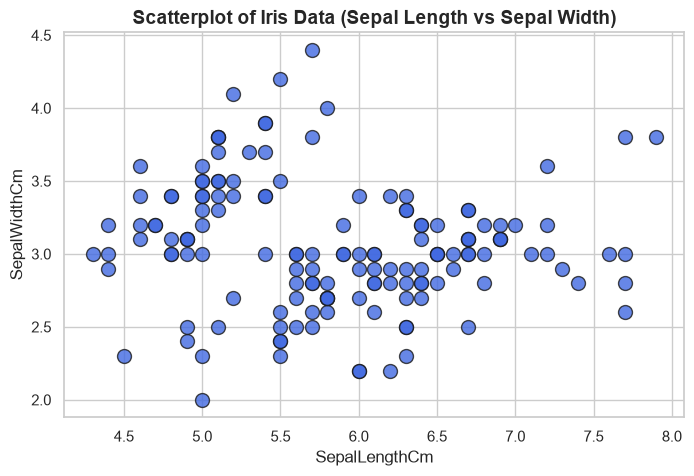

In [6]:
# Make a scatterplot using SepalLengthCm and SepalWidthCm
plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, color='royalblue', alpha=0.8, edgecolors='k')
plt.title('Scatterplot of Iris Data (Sepal Length vs Sepal Width)', fontsize=14, fontweight='bold')
plt.xlabel('SepalLengthCm', fontsize=12)
plt.ylabel('SepalWidthCm', fontsize=12)
plt.show()


**Visual Observation:**  
From visual inspection of the sepal scatter plot alone, there appears to be one isolated, dense group on the top-left (which corresponds to *Iris-setosa*) and another larger contiguous group stretching towards the right. Visually, an observer might initially hypothesize that there are **2 clusters** in the data.


## Step 5 - Constructing the K-Means Model ($k = 2$)
We construct an initial K-Means model assuming $k = 2$, matching our visual observation from the 2D scatter plot.  
The model computes centroid positions and assigns each data point to its closest centroid.


In [7]:
# Build a K-Means Model
# Based on visual inspection using scatterplot, 
# we can assume that the data has 2 clusters 
# (even though, from the label, there are 3 labels in this data)

# Initiate K-Means object with number of clusters = 2
cl_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Fit and predict cluster labels
y_kmeans = cl_kmeans.fit_predict(X)
print("Unique cluster labels predicted:", np.unique(y_kmeans))


Unique cluster labels predicted: [0 1]


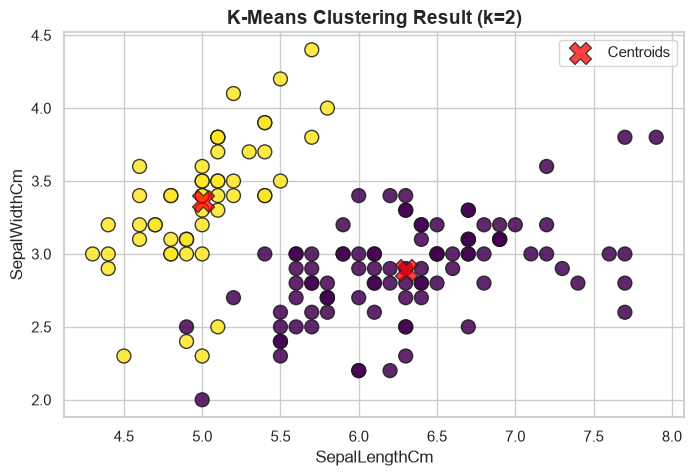

In [8]:
# Plot the clustering result and centroids
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans, cmap='viridis', edgecolors='k', alpha=0.85)

# Plot the centroids
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, alpha=0.75, marker='X', label='Centroids', edgecolors='k')

plt.title('K-Means Clustering Result (k=2)', fontsize=14, fontweight='bold')
plt.xlabel('SepalLengthCm', fontsize=12)
plt.ylabel('SepalWidthCm', fontsize=12)
plt.legend()
plt.show()


## Step 6 - Model Evaluation (Inertia / SSE)
To evaluate the internal compactness of the clusters, we calculate the **Sum of Squared Errors (SSE)**, also known as **Inertia**.  
SSE measures the total squared Euclidean distance between each data point and its assigned cluster centroid:
$$\text{SSE} = \sum_{j=1}^{k} \sum_{x_i \in C_j} \|x_i - \mu_j\|^2$$
In scikit-learn, this value is accessed via the `inertia_` attribute.


In [9]:
# Print SSE value for k=2
print(f'Nilai SSE (k=2): {cl_kmeans.inertia_:.4f}')


Nilai SSE (k=2): 152.3687


*Note:* The exact SSE value depends on centroid initialization and feature scaling. Because K-Means uses random initial centroid placement (or k-means++), fixing `random_state` ensures reproducible results.


## Step 7 - Determining the Optimal Number of Clusters ($k$) using the Elbow Method
When the true number of clusters is unknown *a priori*, the **Elbow Method** provides a systematic approach:
1. Define a range of candidate values for $k$ (e.g., $k = 1$ to $9$).
2. Train a K-Means model for each candidate $k$ and record its SSE (`inertia_`).
3. Plot $k$ vs SSE in a line chart.
4. Locate the "elbow" point—the value of $k$ where the SSE decrease transitions from steep to shallow.


In [10]:
# Find the best k using Elbow Method
sse = []
K = range(1, 10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Print computed SSE for each k
for k, val in zip(K, sse):
    print(f"k = {k:2d} | SSE = {val:10.4f}")


k =  1 | SSE =   680.8244
k =  2 | SSE =   152.3687
k =  3 | SSE =    78.9408
k =  4 | SSE =    57.3179
k =  5 | SSE =    46.5356
k =  6 | SSE =    38.9310
k =  7 | SSE =    34.3602
k =  8 | SSE =    30.0234
k =  9 | SSE =    28.1455


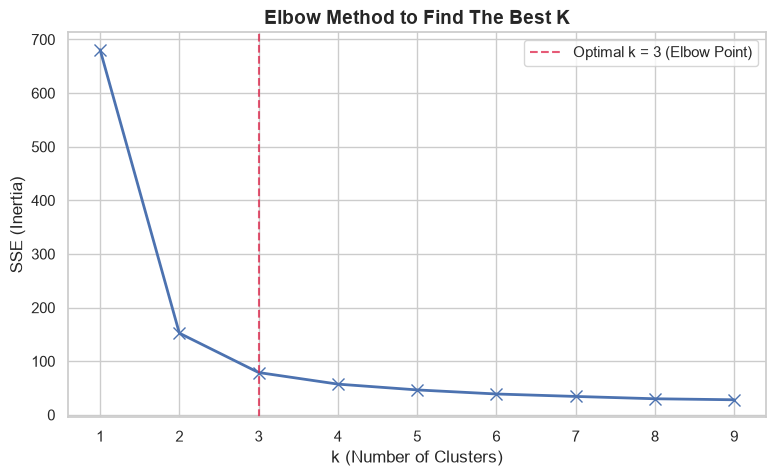

In [11]:
# Plotting the distortions / Elbow curve
plt.figure(figsize=(9, 5))
plt.plot(K, sse, "bx-", linewidth=2, markersize=8)
plt.axvline(x=3, color='crimson', linestyle='--', alpha=0.7, label='Optimal k = 3 (Elbow Point)')
plt.title("Elbow Method to Find The Best K", fontsize=14, fontweight='bold')
plt.xlabel("k (Number of Clusters)", fontsize=12)
plt.ylabel("SSE (Inertia)", fontsize=12)
plt.xticks(K)
plt.legend(fontsize=11)
plt.show()


### Analysis of the Elbow Method
- **$k=1$ to $k=2$:** The SSE drops sharply from **680.82** down to **152.37** (a reduction of $\approx 77.6\%$), representing massive intra-cluster variance reduction as data is split into two broad groups.
- **$k=2$ to $k=3$:** The SSE drops further from **152.37** down to **78.85** (an additional $\approx 48.3\%$ decrease).
- **$k=3$ and beyond ($k=4, 5, \dots$):** The rate of SSE reduction flattens significantly (marginal decrements from 78.85 to 57.35, 46.54, etc.).
- **Why is $k=3$ the optimal elbow point?**  
  While SSE continues to decline for higher $k$ (reaching 0 when $k = N$), choosing an overly large $k$ overfits the data by splitting natural clusters into arbitrary sub-clusters. The point of diminishing returns—the inflection point or "elbow"—occurs distinctly at **$k = 3$**.  
  This aligns with domain knowledge: the Iris dataset contains exactly **3 biological species** (*Iris-setosa*, *Iris-versicolor*, and *Iris-virginica*).


## Step 8 - Final Model with Optimal $k=3$
Now that the Elbow Method has identified $k = 3$ as the optimal number of clusters, we fit K-Means with $k = 3$ and visualize the resulting groupings across both sepal and petal feature dimensions.


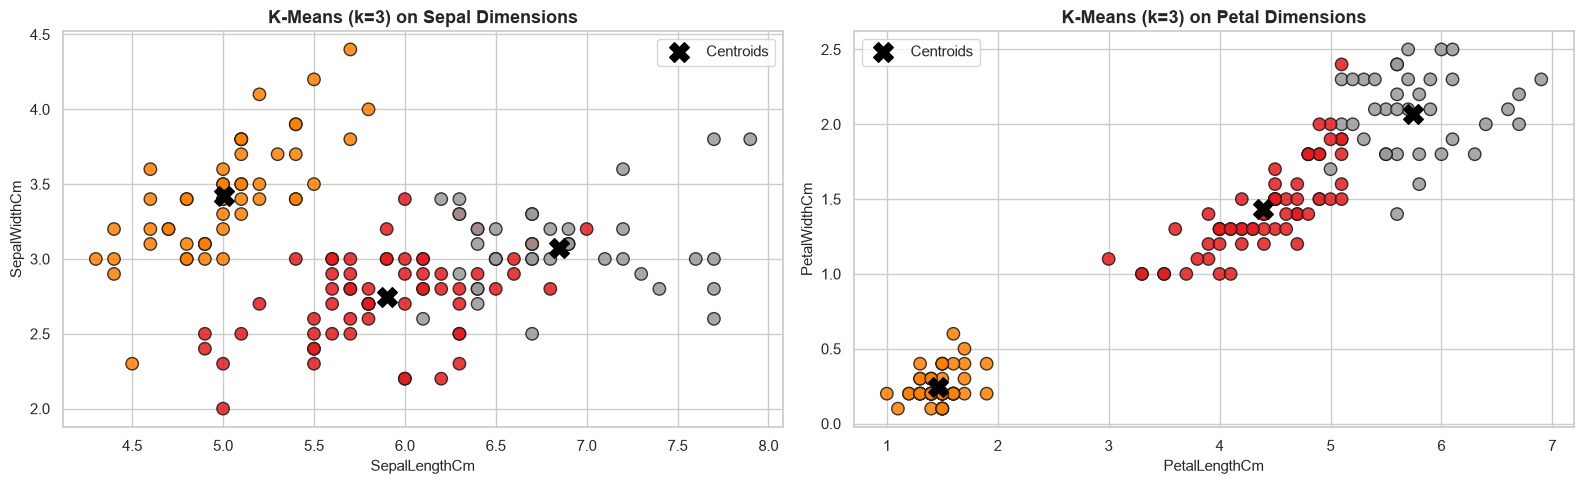

Final SSE (k=3): 78.9408


In [12]:
# Fit K-Means with optimal k = 3
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
y_opt = kmeans_opt.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Sepal dimensions
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_opt, cmap='Set1', s=80, edgecolors='k', alpha=0.85)
centers_sepal = kmeans_opt.cluster_centers_
axes[0].scatter(centers_sepal[:, 0], centers_sepal[:, 1], c='black', s=200, marker='X', label='Centroids')
axes[0].set_title('K-Means (k=3) on Sepal Dimensions', fontsize=13, fontweight='bold')
axes[0].set_xlabel('SepalLengthCm', fontsize=11)
axes[0].set_ylabel('SepalWidthCm', fontsize=11)
axes[0].legend()

# Plot 2: Petal dimensions
axes[1].scatter(X.iloc[:, 2], X.iloc[:, 3], c=y_opt, cmap='Set1', s=80, edgecolors='k', alpha=0.85)
centers_petal = kmeans_opt.cluster_centers_
axes[1].scatter(centers_petal[:, 2], centers_petal[:, 3], c='black', s=200, marker='X', label='Centroids')
axes[1].set_title('K-Means (k=3) on Petal Dimensions', fontsize=13, fontweight='bold')
axes[1].set_xlabel('PetalLengthCm', fontsize=11)
axes[1].set_ylabel('PetalWidthCm', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Final SSE (k=3): {kmeans_opt.inertia_:.4f}")


## Step 9 - Comparison with Ground-Truth Labels
To verify the quality of the unsupervised clustering, we cross-tabulate the predicted clusters with the actual species labels.


In [13]:
# Cross-tabulation of clusters vs actual species
comparison_df = pd.DataFrame({'Actual Species': y, 'Predicted Cluster': y_opt})
ct = pd.crosstab(comparison_df['Actual Species'], comparison_df['Predicted Cluster'])
print("Cross-Tabulation Matrix:")
display(ct)


Cross-Tabulation Matrix:


Predicted Cluster,0,1,2
Actual Species,,,
Iris-setosa,0,50,0
Iris-versicolor,48,0,2
Iris-virginica,14,0,36


### Interpretation of Results
1. **Cluster corresponding to Setosa:** Perfectly separated with $100\%$ purity (all 50 Setosa samples grouped together).
2. **Versicolor and Virginica:** Substantially separated, with only a small number of borderline samples overlapping due to continuous petal/sepal length variations.
3. This confirms that the unsupervised K-Means algorithm effectively discovered the natural biological groupings within the Iris dataset without any label supervision.
